<a href="https://colab.research.google.com/github/digvijaysingh2111/Ai-and-Society-Assignment/blob/main/German_Credit_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CSET485 – AI and Society | Assignment #1 | German Credit Data

**How to use this notebook**
1. Change `ROLL_LAST3` in the first code cell to the last 3 digits of your roll number (this is the random seed).
2. `Runtime → Run all`. Every number you need for the PDF is printed, and tables/figures are saved to the `outputs/` folder.
3. Search for the cells marked **`# <-- YOU CAN CHANGE`** (e.g. which variable to drop in 2.2, which threshold to defend in Q7).

> Convention used throughout: `approval = 1` means *good credit / approve*. A "flag" means **predicted approve (high score)**.
> For Part 1, the assignment says "high risk if ≥ threshold". In this dataset a high score means *low* risk, so I use "flagged = predicted approve" for both models. The mismatch counts are identical under either labelling, as long as both models use the same one.

## 0. Setup

In [19]:
# ============ CONFIG ============
ROLL_LAST3 = S24CSEU2823     # <-- YOU MUST CHANGE: last 3 digits of your roll number
SEED = 823
# ================================

import os, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import accuracy_score, roc_auc_score

warnings.filterwarnings("ignore")
np.random.seed(SEED)
os.makedirs("outputs", exist_ok=True)
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

RESULTS = {}   # every headline number gets stored here -> printed at the end ("cheat sheet")
print("SEED =", SEED)

SEED = 123


In [20]:
# ---------- Helper functions used in several parts ----------
def fit_logit(X, y):
    """Logistic regression via statsmodels (gives coefficients, CIs, p-values).
    Drops constant columns; falls back to BFGS if Newton fails (e.g. separation)."""
    X = X.loc[:, X.std() > 0]
    Xc = sm.add_constant(X, has_constant="add")
    try:
        return sm.Logit(y, Xc).fit(disp=0, maxiter=200)
    except Exception:
        return sm.Logit(y, Xc).fit(disp=0, method="bfgs", maxiter=5000)

def predict_logit(res, X):
    names = [n for n in res.model.exog_names if n != "const"]
    return np.asarray(res.predict(sm.add_constant(X[names], has_constant="add")))

def coef_table(res):
    ci = res.conf_int()
    ci = pd.DataFrame(np.asarray(ci), index=res.params.index, columns=["ci_low", "ci_high"])
    return pd.DataFrame({"coef": res.params, "se": res.bse, "ci_low": ci["ci_low"],
                         "ci_high": ci["ci_high"], "p": res.pvalues})

def save_fig(name):
    plt.savefig(f"outputs/{name}.png", dpi=160, bbox_inches="tight")

## 1. Load data

In [21]:
cols = ["checking_status", "duration", "credit_history", "purpose", "credit_amount", "savings",
        "employment", "installment_rate", "personal_status_sex", "other_debtors", "residence_since",
        "property", "age", "other_installment", "housing", "existing_credits", "job",
        "num_dependents", "telephone", "foreign_worker", "class"]

URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/statlog/german/german.data"
df = None
for path in ["german.data", URL]:            # local copy first, then UCI
    try:
        df = pd.read_csv(path, sep=r"\s+", header=None, names=cols)
        print("Loaded from:", path); break
    except Exception as e:
        print("Could not load", path, "->", type(e).__name__)
if df is None:                                # last resort: upload german.data manually
    from google.colab import files
    up = files.upload()
    df = pd.read_csv(list(up.keys())[0], sep=r"\s+", header=None, names=cols)

print(df.shape)
df.head()

Could not load german.data -> FileNotFoundError
Loaded from: https://archive.ics.uci.edu/ml/machine-learning-databases/statlog/german/german.data
(1000, 21)


,checking_status,duration,credit_history,purpose,credit_amount,savings,employment,installment_rate,personal_status_sex,other_debtors,residence_since,property,age,other_installment,housing,existing_credits,job,num_dependents,telephone,foreign_worker,class
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,4,A121,67,A143,A152,2,A173,1,A192,A201,1
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,2,A121,22,A143,A152,1,A173,1,A191,A201,2
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,3,A121,49,A143,A152,1,A172,2,A191,A201,1
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,4,A122,45,A143,A153,1,A173,2,A191,A201,1
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,4,A124,53,A143,A153,2,A173,2,A191,A201,2


In [22]:
# Target and derived columns
df["approval"] = (df["class"] == 1).astype(int)          # raw: 1 = good, 2 = bad  ->  1 = approve, 0 = reject
df["sex"] = np.where(df["personal_status_sex"] == "A92", "female", "male")   # A92 is the only female code
df["age_group"] = np.where(df["age"] < 25, "<25", ">=25")

print("Approval rate (class balance):", round(df["approval"].mean(), 4))
print(df["sex"].value_counts().to_dict(), "| age<25:", int((df["age"] < 25).sum()))
RESULTS["n_total"] = int(len(df)); RESULTS["approval_rate_overall"] = float(df["approval"].mean())

Approval rate (class balance): 0.7
{'male': 690, 'female': 310} | age<25: 149


## 2. Data preprocessing (document this in the PDF)
* **Missing values** – checked below. German Credit has none. Codes such as `A14` (no checking account) and `A65` (unknown savings) are *real categories*, so they are kept.
* **Categorical encoding** – one-hot with `drop_first=True` (avoids the dummy-variable trap).
* **Scaling** – numeric features standardised with `StandardScaler` **fit on the training set only**.
* **Outliers** – `credit_amount` is right-skewed; checked with the IQR rule and handled with a `log1p` transform (nothing deleted, since 1,000 rows is small and large loans are legitimate).
* **Split** – 70/30, `random_state = SEED`, stratified on the target.

Missing values per column (total): 0
Duplicate rows: 0


,column,min,max,skew,n_IQR_outliers
0,duration,4,72,1.0942,70
1,credit_amount,250,18424,1.9496,72
2,installment_rate,1,4,-0.5313,0
3,residence_since,1,4,-0.2726,0
4,age,19,75,1.0207,23
5,existing_credits,1,4,1.2726,6
6,num_dependents,1,2,1.9094,155


credit_amount skew: raw = 1.950  ->  log1p = 0.130


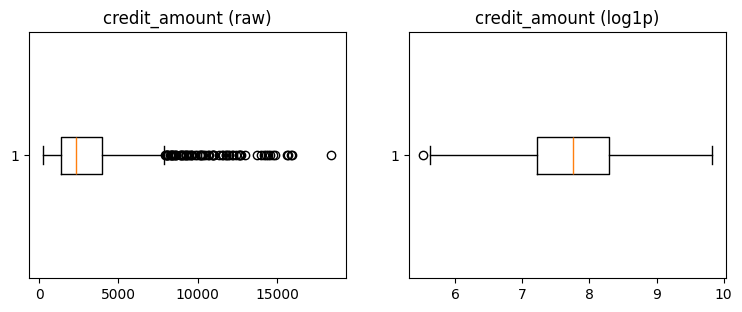

In [23]:
# --- Missing values
print("Missing values per column (total):", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))

# --- Outliers: IQR rule on the numeric columns
NUM_COLS = ["duration", "credit_amount", "installment_rate", "residence_since", "age", "existing_credits", "num_dependents"]
rows = []
for c in NUM_COLS:
    q1, q3 = df[c].quantile([.25, .75]); iqr = q3 - q1
    n_out = int(((df[c] < q1 - 1.5 * iqr) | (df[c] > q3 + 1.5 * iqr)).sum())
    rows.append({"column": c, "min": df[c].min(), "max": df[c].max(), "skew": df[c].skew(), "n_IQR_outliers": n_out})
outlier_tbl = pd.DataFrame(rows); display(outlier_tbl)
outlier_tbl.to_csv("outputs/outlier_table.csv", index=False)

skew_before = df["credit_amount"].skew(); skew_after = np.log1p(df["credit_amount"]).skew()
print(f"credit_amount skew: raw = {skew_before:.3f}  ->  log1p = {skew_after:.3f}")
RESULTS["credit_amount_skew_raw"] = float(skew_before); RESULTS["credit_amount_skew_log"] = float(skew_after)

fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
ax[0].boxplot(df["credit_amount"], vert=False); ax[0].set_title("credit_amount (raw)")
ax[1].boxplot(np.log1p(df["credit_amount"]), vert=False); ax[1].set_title("credit_amount (log1p)")
save_fig("fig_outliers"); plt.show()

In [24]:
# --- Build feature matrix: log-transform credit_amount, one-hot encode, split, then scale (train-only fit)
feature_cols = [c for c in cols if c != "class"]
X_raw = df[feature_cols].copy()
X_raw["credit_amount"] = np.log1p(X_raw["credit_amount"])
for c in NUM_COLS:
    X_raw[c] = X_raw[c].astype(float)
CAT_COLS = [c for c in feature_cols if c not in NUM_COLS]

X_all = pd.get_dummies(X_raw, columns=CAT_COLS, drop_first=True, dtype=float)
y = df["approval"]

idx_train, idx_test = train_test_split(df.index, test_size=0.3, random_state=SEED, stratify=y)
X_train, X_test = X_all.loc[idx_train].copy(), X_all.loc[idx_test].copy()
y_train, y_test = y.loc[idx_train], y.loc[idx_test]

const_cols = X_train.columns[X_train.std() == 0]           # drop dummies that are constant in train
X_train, X_test = X_train.drop(columns=const_cols), X_test.drop(columns=const_cols)

scaler = StandardScaler().fit(X_train[NUM_COLS])           # fit on TRAIN only
X_train[NUM_COLS] = scaler.transform(X_train[NUM_COLS])
X_test[NUM_COLS] = scaler.transform(X_test[NUM_COLS])

df_test = df.loc[idx_test].copy()                          # raw (readable) version of the test rows
print("X_all:", X_all.shape, "| train:", X_train.shape, "| test:", X_test.shape)
print("Train approval rate:", round(y_train.mean(), 4), "| Test approval rate:", round(y_test.mean(), 4))
RESULTS.update(n_train=int(len(X_train)), n_test=int(len(X_test)), n_features=int(X_train.shape[1]),
               test_approval_rate=float(y_test.mean()))

X_all: (1000, 48) | train: (700, 48) | test: (300, 48)
Train approval rate: 0.7 | Test approval rate: 0.7


## 3. Part 1 – Build and compare Model A (OLS) vs Model B (Logistic)

Confusion matrix (rows = Model A flag, cols = Model B flag):


Model B (p >= 0.5),0,1
Model A (pred >= median),,
0,74,76
1,0,150


Median of Model A test predictions : 0.6975   (Model B threshold = 0.5000)
Model A predictions outside [0,1]  : 36  (min 0.052, max 1.322)
Model A flagged (>= median)        : 150  (50.0%)
Model B flagged (p >= 0.5)         : 226  (75.3%)
MISMATCHED cases                   : 76 of 300  (25.33%)
   A=1,B=0: 0   A=0,B=1: 76
Spearman rank corr (predA, pB)     : 0.9705
Median of Model B probabilities    : 0.7682
Accuracy vs truth -> A flag: 0.6400 | B flag: 0.7600
AUC -> A: 0.7418 | B: 0.7231


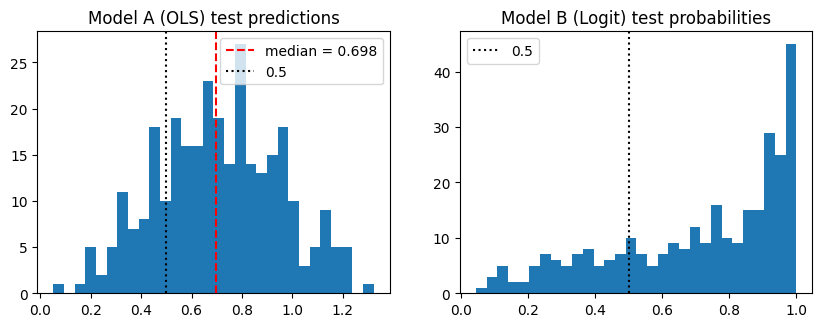

In [25]:
# Model A: OLS on the 0/1 approval variable (a "linear probability model")
ols = LinearRegression().fit(X_train, y_train)
predA = pd.Series(ols.predict(X_test), index=X_test.index)
medA = float(predA.median())
flagA = (predA >= medA).astype(int)                         # flag = predicted approve

# Model B: logistic regression
logit_B = fit_logit(X_train, y_train)
pB = pd.Series(predict_logit(logit_B, X_test), index=X_test.index)
flagB = (pB >= 0.5).astype(int)

cm = pd.crosstab(flagA.rename("Model A (pred >= median)"), flagB.rename("Model B (p >= 0.5)"))
cm = cm.reindex(index=[0, 1], columns=[0, 1], fill_value=0)
print("Confusion matrix (rows = Model A flag, cols = Model B flag):"); display(cm)
cm.to_csv("outputs/part1_confusion_matrix.csv")

n = len(flagA); mism = int((flagA != flagB).sum())
a1b0 = int(((flagA == 1) & (flagB == 0)).sum()); a0b1 = int(((flagA == 0) & (flagB == 1)).sum())
print(f"Median of Model A test predictions : {medA:.4f}   (Model B threshold = 0.5000)")
print(f"Model A predictions outside [0,1]  : {(predA < 0).sum() + (predA > 1).sum()}  (min {predA.min():.3f}, max {predA.max():.3f})")
print(f"Model A flagged (>= median)        : {int(flagA.sum())}  ({flagA.mean()*100:.1f}%)")
print(f"Model B flagged (p >= 0.5)         : {int(flagB.sum())}  ({flagB.mean()*100:.1f}%)")
print(f"MISMATCHED cases                   : {mism} of {n}  ({mism/n*100:.2f}%)")
print(f"   A=1,B=0: {a1b0}   A=0,B=1: {a0b1}")
print(f"Spearman rank corr (predA, pB)     : {stats.spearmanr(predA, pB)[0]:.4f}")
print(f"Median of Model B probabilities    : {pB.median():.4f}")
print(f"Accuracy vs truth -> A flag: {accuracy_score(y_test, flagA):.4f} | B flag: {accuracy_score(y_test, flagB):.4f}")
print(f"AUC -> A: {roc_auc_score(y_test, predA):.4f} | B: {roc_auc_score(y_test, pB):.4f}")

RESULTS["part1"] = dict(median_predA=medA, mismatch_n=mism, mismatch_pct=mism/n*100, A1B0=a1b0, A0B1=a0b1,
    flaggedA_n=int(flagA.sum()), flaggedB_n=int(flagB.sum()), flaggedB_pct=float(flagB.mean()*100),
    predA_outside_01=int((predA < 0).sum() + (predA > 1).sum()), median_pB=float(pB.median()),
    spearman=float(stats.spearmanr(predA, pB)[0]), acc_A_flag=float(accuracy_score(y_test, flagA)),
    acc_B_flag=float(accuracy_score(y_test, flagB)), auc_A=float(roc_auc_score(y_test, predA)),
    auc_B=float(roc_auc_score(y_test, pB)))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].hist(predA, bins=30); ax[0].axvline(medA, color="r", ls="--", label=f"median = {medA:.3f}")
ax[0].axvline(0.5, color="k", ls=":", label="0.5"); ax[0].set_title("Model A (OLS) test predictions"); ax[0].legend()
ax[1].hist(pB, bins=30); ax[1].axvline(0.5, color="k", ls=":", label="0.5")
ax[1].set_title("Model B (Logit) test probabilities"); ax[1].legend()
save_fig("fig_part1_distributions"); plt.show()

## 4. Part 2.1 – Simpson's paradox / subgroup effects
The code scans several demographic splits × predictors. Subgroup fits use a **small, interpretable feature set** to avoid separation with small samples. Features are standardised, so coefficients are *per +1 SD* (log-odds of approval).
Use the full 1,000 rows here, as the task says "full dataset".

In [26]:
SMALL_FEATS = ["duration", "credit_amount", "installment_rate", "age"] + [c for c in ["checking_status_A14"] if c in X_all.columns]
X_full_s = X_all.copy()
X_full_s[NUM_COLS] = StandardScaler().fit_transform(X_all[NUM_COLS])

SPLITS = {   # name: (mask for group A, mask for group B)
    "sex (A=male, B=female)":          (df.sex == "male", df.sex == "female"),
    "age (A>=25, B<25)":               (df.age >= 25, df.age < 25),
    "age (A>=35, B<35)":               (df.age >= 35, df.age < 35),
    "housing (A=own, B=not own)":      (df.housing == "A152", df.housing != "A152"),
    "job (A=skilled+, B=unskilled)":   (df.job.isin(["A173", "A174"]), df.job.isin(["A171", "A172"])),
}

full_res = fit_logit(X_full_s[SMALL_FEATS], y)
full_tbl = coef_table(full_res)
scan = []
for sname, (mA, mB) in SPLITS.items():
    rA, rB = fit_logit(X_full_s.loc[mA, SMALL_FEATS], y[mA]), fit_logit(X_full_s.loc[mB, SMALL_FEATS], y[mB])
    tA, tB = coef_table(rA), coef_table(rB)
    for f in SMALL_FEATS:
        if f in tA.index and f in tB.index:
            bf, bA, bB = full_tbl.loc[f, "coef"], tA.loc[f, "coef"], tB.loc[f, "coef"]
            z = (bA - bB) / np.sqrt(tA.loc[f, "se"]**2 + tB.loc[f, "se"]**2)
            revA = (np.sign(bA) != np.sign(bf)) and tA.loc[f, "p"] < .05
            revB = (np.sign(bB) != np.sign(bf)) and tB.loc[f, "p"] < .05
            scan.append(dict(split=sname, predictor=f, nA=int(mA.sum()), nB=int(mB.sum()), b_full=bf, b_A=bA, b_B=bB,
                             p_A=tA.loc[f, "p"], p_B=tB.loc[f, "p"], z_diff=z, p_diff=2*(1-stats.norm.cdf(abs(z))),
                             sig_reversal=bool(revA or revB)))
scan_df = pd.DataFrame(scan)
scan_df["abs_z"] = scan_df["z_diff"].abs()
scan_df = scan_df.sort_values(["sig_reversal", "abs_z"], ascending=False).reset_index(drop=True)
display(scan_df.drop(columns="abs_z").head(12))
scan_df.to_csv("outputs/part21_scan.csv", index=False)
print("Any significant sign reversal found?", bool(scan_df["sig_reversal"].any()))

,split,predictor,nA,nB,b_full,b_A,b_B,p_A,p_B,z_diff,p_diff,sig_reversal
0,"sex (A=male, B=female)",age,690,310,0.1920,0.0020,0.4878,0.9835,0.0011,-2.7459,0.0060,False
1,"age (A>=35, B<35)",credit_amount,452,548,-0.0532,-0.3120,0.1216,0.0634,0.4192,-1.9218,0.0546,False
2,"job (A=skilled+, B=unskilled)",installment_rate,778,222,-0.2185,-0.1250,-0.5166,0.2066,0.0073,1.8073,0.0707,False
3,"job (A=skilled+, B=unskilled)",age,778,222,0.1920,0.1441,0.3938,0.1086,0.0194,-1.3081,0.1908,False
4,"age (A>=25, B<25)",checking_status_A14,851,149,1.7162,1.7871,1.1348,0.0000,0.0156,1.2797,0.2006,False
5,"housing (A=own, B=not own)",installment_rate,713,287,-0.2185,-0.1411,-0.3724,0.1873,0.0129,1.2562,0.2091,False
6,"age (A>=25, B<25)",duration,851,149,-0.4167,-0.3510,-0.7108,0.0019,0.0083,1.2318,0.2180,False
7,"job (A=skilled+, B=unskilled)",checking_status_A14,778,222,1.7162,1.7906,1.2636,0.0000,0.0022,1.1451,0.2522,False
8,"job (A=skilled+, B=unskilled)",credit_amount,778,222,-0.0532,-0.1087,0.1932,0.3891,0.4533,-1.0523,0.2926,False
9,"age (A>=35, B<35)",age,452,548,0.1920,-0.0989,0.2437,0.4906,0.4079,-1.0459,0.2956,False


Any significant sign reversal found? False


In [27]:
CHOSEN_SPLIT = None   # <-- YOU CAN CHANGE, e.g. "sex (A=male, B=female)"; None = auto-pick top row of the scan
CHOSEN_PRED  = None   # <-- YOU CAN CHANGE, e.g. "duration"

split_name = CHOSEN_SPLIT or scan_df.loc[0, "split"]
pred_name  = CHOSEN_PRED  or scan_df.loc[0, "predictor"]
mA, mB = SPLITS[split_name]
print(f"Chosen split: {split_name} | predictor: {pred_name}\n")

rA, rB = fit_logit(X_full_s.loc[mA, SMALL_FEATS], y[mA]), fit_logit(X_full_s.loc[mB, SMALL_FEATS], y[mB])
detail = []
for name, tbl, n_ in [("Full dataset", full_tbl, len(df)), ("Subgroup A", coef_table(rA), int(mA.sum())), ("Subgroup B", coef_table(rB), int(mB.sum()))]:
    r = tbl.loc[pred_name]
    detail.append(dict(model=name, n=n_, coef=r.coef, se=r.se, ci_low=r.ci_low, ci_high=r.ci_high, p=r.p))
detail = pd.DataFrame(detail); display(detail)
detail.to_csv("outputs/part21_chosen_coefficients.csv", index=False)

# Formal test of difference: interaction term in the pooled model
Xi = X_full_s[SMALL_FEATS].copy(); Xi["group_B"] = mB.astype(float).values; Xi["interaction"] = Xi[pred_name] * Xi["group_B"]
ri = sm.Logit(y, sm.add_constant(Xi)).fit(disp=0)
print(f"Interaction ({pred_name} x group B): coef = {ri.params['interaction']:.4f}, p = {ri.pvalues['interaction']:.4f}")
print("Approval rate: group A = %.3f | group B = %.3f" % (y[mA].mean(), y[mB].mean()))
print("\nAll coefficients, full model:"); display(full_tbl)

RESULTS["part21"] = dict(split=split_name, predictor=pred_name, table=detail.round(4).to_dict("records"),
    interaction_coef=float(ri.params["interaction"]), interaction_p=float(ri.pvalues["interaction"]),
    approval_rate_A=float(y[mA].mean()), approval_rate_B=float(y[mB].mean()))

Chosen split: sex (A=male, B=female) | predictor: age



,model,n,coef,se,ci_low,ci_high,p
0,Full dataset,1000,0.1920,0.0784,0.0384,0.3456,0.0143
1,Subgroup A,690,0.0020,0.0955,-0.1851,0.1891,0.9835
2,Subgroup B,310,0.4878,0.1490,0.1958,0.7798,0.0011


Interaction (age x group B): coef = 0.4678, p = 0.0073
Approval rate: group A = 0.723 | group B = 0.648

All coefficients, full model:


,coef,se,ci_low,ci_high,p
const,0.3725,0.0858,0.2043,0.5407,0.0000
duration,-0.4167,0.1031,-0.6188,-0.2146,0.0001
credit_amount,-0.0532,0.1099,-0.2686,0.1622,0.6282
installment_rate,-0.2185,0.0865,-0.3881,-0.0489,0.0116
age,0.1920,0.0784,0.0384,0.3456,0.0143
checking_status_A14,1.7162,0.1820,1.3595,2.0729,0.0000


## 5. Part 2.2 – Omitted-variable bias
Fit the full logistic model and a reduced one without a suspected confounder. `credit_amount` is a natural choice because it is strongly correlated with `duration` (bigger loans run longer).

In [28]:
DROP_COLS = ["credit_amount"]   # <-- YOU CAN CHANGE, e.g. ["checking_status_A12","checking_status_A13","checking_status_A14"]

# Justify the choice: how correlated is the dropped variable with the other predictors?
corr = X_train.corr()[DROP_COLS].drop(index=DROP_COLS).abs().max(axis=1).sort_values(ascending=False)
print("Largest |correlations| of the dropped variable(s) with other predictors:"); display(corr.head(6))

full22 = fit_logit(X_train, y_train)
red22 = fit_logit(X_train.drop(columns=DROP_COLS), y_train)

b, a = full22.params.drop("const"), red22.params.drop("const")
common = b.index.intersection(a.index)
cmp = pd.DataFrame({"before": b[common], "after": a[common]})
cmp["abs_change"] = cmp["after"] - cmp["before"]
cmp["pct_change"] = cmp["abs_change"] / cmp["before"].abs() * 100
cmp["p_before"] = full22.pvalues[common]

print("Top 10 by ABSOLUTE shift (log-odds):"); top_abs = cmp.reindex(cmp["abs_change"].abs().sort_values(ascending=False).index).head(10); display(top_abs)
print("Top 10 by PERCENT shift, restricted to predictors with |before| >= 0.10 (avoids dividing by ~0):")
big = cmp[cmp["before"].abs() >= 0.10]
top_pct = big.reindex(big["pct_change"].abs().sort_values(ascending=False).index).head(10); display(top_pct)
cmp.to_csv("outputs/part22_full_comparison.csv"); top_abs.to_csv("outputs/part22_top_abs.csv"); top_pct.to_csv("outputs/part22_top_pct.csv")

lr = 2 * (full22.llf - red22.llf); lr_p = 1 - stats.chi2.cdf(lr, df=len(DROP_COLS))
print(f"Likelihood-ratio test (does the dropped variable matter?): LR = {lr:.3f}, df = {len(DROP_COLS)}, p = {lr_p:.4g}")
auc_full = roc_auc_score(y_test, predict_logit(full22, X_test)); auc_red = roc_auc_score(y_test, predict_logit(red22, X_test))
print(f"Test AUC full = {auc_full:.4f} | reduced = {auc_red:.4f}  (predictive accuracy barely changes even though coefficients do)")

RESULTS["part22"] = dict(dropped=DROP_COLS, LR=float(lr), LR_p=float(lr_p), auc_full=float(auc_full), auc_reduced=float(auc_red),
                         top_abs=top_abs.round(4).reset_index().rename(columns={"index": "predictor"}).to_dict("records"),
                         top_pct=top_pct.round(4).reset_index().rename(columns={"index": "predictor"}).to_dict("records"))

Largest |correlations| of the dropped variable(s) with other predictors:


,0
duration,0.6597
installment_rate,0.3078
telephone_A192,0.2875
purpose_A41,0.2682
job_A174,0.2419
property_A124,0.2400


Top 10 by ABSOLUTE shift (log-odds):


,before,after,abs_change,pct_change,p_before
purpose_A48,23.7035,23.8846,0.1811,0.7641,0.9996
purpose_A410,24.5408,24.3610,-0.1798,-0.7325,0.9996
duration,-0.4432,-0.5446,-0.1014,-22.8866,0.0029
purpose_A44,0.2336,0.3174,0.0837,35.8404,0.7939
property_A124,-0.9387,-1.0205,-0.0818,-8.7134,0.0868
purpose_A41,1.9229,1.8413,-0.0816,-4.2426,0.0000
credit_history_A31,0.1508,0.2229,0.0721,47.8325,0.8236
installment_rate,-0.3398,-0.2809,0.0589,17.3345,0.0059
telephone_A192,0.0804,0.0241,-0.0562,-69.9635,0.7454
purpose_A42,0.8795,0.8335,-0.0460,-5.2359,0.0058


Top 10 by PERCENT shift, restricted to predictors with |before| >= 0.10 (avoids dividing by ~0):


,before,after,abs_change,pct_change,p_before
credit_history_A31,0.1508,0.2229,0.0721,47.8325,0.8236
purpose_A44,0.2336,0.3174,0.0837,35.8404,0.7939
duration,-0.4432,-0.5446,-0.1014,-22.8866,0.0029
employment_A75,-0.1328,-0.1607,-0.0279,-21.0405,0.7952
property_A123,-0.2145,-0.2546,-0.0401,-18.7149,0.4542
installment_rate,-0.3398,-0.2809,0.0589,17.3345,0.0059
job_A174,0.2793,0.2421,-0.0372,-13.3080,0.7268
purpose_A46,-0.1297,-0.1141,0.0156,12.0607,0.7884
property_A122,-0.2625,-0.2891,-0.0265,-10.1104,0.4012
property_A124,-0.9387,-1.0205,-0.0818,-8.7134,0.0868


Likelihood-ratio test (does the dropped variable matter?): LR = 1.157, df = 1, p = 0.2821
Test AUC full = 0.7231 | reduced = 0.7210  (predictive accuracy barely changes even though coefficients do)


## 6. Part 2.3 – Adversarial subset (confident wrong predictions)

In [29]:
y_t = y_test
fp = (pB >= 0.75) & (y_t == 0)          # confident "approve", actually bad
fn = (pB <= 0.25) & (y_t == 1)          # confident "reject", actually good
bad = fp | fn
n_bad = int(bad.sum())
print(f"High-confidence wrong predictions: {n_bad} of {len(pB)} ({n_bad/len(pB)*100:.2f}%)  | FP-type: {int(fp.sum())}, FN-type: {int(fn.sum())}")

sub_idx = bad[bad].index
if n_bad > 50:
    sub_idx = pd.Index(np.random.RandomState(SEED).choice(sub_idx, 50, replace=False))
    print("More than 50 -> randomly sampled 50 (random_state = SEED)")
else:
    print(f"Only {n_bad} such rows -> using ALL of them")
sub = df_test.loc[sub_idx]; rest = df_test.drop(index=sub_idx)

# Numeric comparison
num_rows = []
for c in ["age", "duration", "credit_amount"]:
    num_rows.append(dict(variable=c, subset_mean=sub[c].mean(), test_mean=df_test[c].mean(),
                         subset_median=sub[c].median(), test_median=df_test[c].median(),
                         mannwhitney_p=stats.mannwhitneyu(sub[c], rest[c]).pvalue))
display(pd.DataFrame(num_rows))

# Categorical comparison (levels with >= 5% share in the test set)
cat_cols = [c for c in df_test.columns if not pd.api.types.is_numeric_dtype(df_test[c]) and c != "class"]
lv = []
for c in cat_cols:
    for lvl in df_test[c].unique():
        s_sub, s_all = (sub[c] == lvl).mean(), (df_test[c] == lvl).mean()
        if s_all < 0.05: continue
        a_ = int((sub[c] == lvl).sum()); c_ = int((rest[c] == lvl).sum())
        p_ = stats.fisher_exact([[a_, len(sub) - a_], [c_, len(rest) - c_]])[1]
        lv.append(dict(variable=c, level=lvl, share_subset_pct=s_sub*100, share_test_pct=s_all*100,
                       diff_pp=(s_sub - s_all)*100, fisher_p=p_))
lv = pd.DataFrame(lv); lv["abs_diff"] = lv.diff_pp.abs()
lv = lv.sort_values("abs_diff", ascending=False).drop(columns="abs_diff").reset_index(drop=True)
print("\nLevels most over/under-represented in the adversarial subset:"); display(lv.head(12))
lv.to_csv("outputs/part23_level_comparison.csv", index=False)

print("\nSex split  -> subset:", sub.sex.value_counts(normalize=True).round(3).to_dict(), "| test:", df_test.sex.value_counts(normalize=True).round(3).to_dict())
print("Age<25 share -> subset: %.1f%% | test: %.1f%%" % ((sub.age < 25).mean()*100, (df_test.age < 25).mean()*100))

# Calibration table: does the model's confidence match reality?
bins = pd.cut(pB, [0, .25, .5, .75, 1.0], include_lowest=True)
calib = pd.DataFrame({"n": pB.groupby(bins).size(), "mean_pred_prob": pB.groupby(bins).mean(), "actual_approval_rate": y_t.groupby(bins).mean()})
print("\nCalibration of Model B on the test set:"); display(calib)

print("\nModel B coefficients (standardised features), 10 smallest p-values:")
display(coef_table(logit_B).sort_values("p").head(10))

RESULTS["part23"] = dict(n_bad=n_bad, pct_bad=n_bad/len(pB)*100, n_fp=int(fp.sum()), n_fn=int(fn.sum()), subset_size=int(len(sub)),
    subset_mean_age=float(sub.age.mean()), test_mean_age=float(df_test.age.mean()),
    subset_pct_female=float((sub.sex == "female").mean()*100), test_pct_female=float((df_test.sex == "female").mean()*100),
    top_levels=lv.head(6).round(3).to_dict("records"))

High-confidence wrong predictions: 31 of 300 (10.33%)  | FP-type: 26, FN-type: 5
Only 31 such rows -> using ALL of them


,variable,subset_mean,test_mean,subset_median,test_median,mannwhitney_p
0,age,35.1613,34.9867,31.0000,32.0000,0.7452
1,duration,23.2258,20.6167,18.0000,18.0000,0.2329
2,credit_amount,"5,019.7097","3,125.7900","3,021.0000","2,319.0000",0.0129



Levels most over/under-represented in the adversarial subset:


,variable,level,share_subset_pct,share_test_pct,diff_pp,fisher_p
0,job,A174,35.4839,15.0000,20.4839,0.0023
1,other_installment,A143,61.2903,79.0000,-17.7097,0.0179
2,credit_history,A34,12.9032,28.3333,-15.4301,0.0566
3,personal_status_sex,A93,38.7097,52.0000,-13.2903,0.1317
4,other_installment,A141,29.0323,16.6667,12.3656,0.0712
5,job,A172,9.6774,21.0000,-11.3226,0.1594
6,purpose,A40,12.9032,24.0000,-11.0968,0.1813
7,job,A173,51.6129,62.3333,-10.7204,0.2402
8,savings,A61,64.5161,54.0000,10.5161,0.2556
9,checking_status,A12,41.9355,31.6667,10.2688,0.2223



Sex split  -> subset: {'male': 0.613, 'female': 0.387} | test: {'male': 0.69, 'female': 0.31}
Age<25 share -> subset: 19.4% | test: 15.7%

Calibration of Model B on the test set:


,n,mean_pred_prob,actual_approval_rate
"(-0.001, 0.25]",21,0.1643,0.2381
"(0.25, 0.5]",53,0.3827,0.4340
"(0.5, 0.75]",65,0.6397,0.7231
"(0.75, 1.0]",161,0.9094,0.8385



Model B coefficients (standardised features), 10 smallest p-values:


,coef,se,ci_low,ci_high,p
checking_status_A14,1.8992,0.2839,1.3426,2.4557,0.0000
purpose_A41,1.9229,0.4641,1.0134,2.8324,0.0000
duration,-0.4432,0.1486,-0.7345,-0.1519,0.0029
const,-3.1691,1.0800,-5.2858,-1.0524,0.0033
purpose_A43,0.8673,0.3046,0.2702,1.4643,0.0044
credit_history_A34,1.4698,0.5255,0.4398,2.4998,0.0052
purpose_A42,0.8795,0.3189,0.2545,1.5045,0.0058
checking_status_A13,1.1506,0.4178,0.3317,1.9695,0.0059
installment_rate,-0.3398,0.1234,-0.5816,-0.0979,0.0059
savings_A65,0.8380,0.3299,0.1915,1.4846,0.0111


## 7. Part 2.4 – Fairness trade-off sweep
Positive prediction (Ŷ = 1) means **approve**. Group A is the reference group in every ratio (A / B).
Ratios are `NaN` when a denominator is 0 or undefined (e.g. a group gets no approvals at t = 0.95); mention this in the report.

In [30]:
SENSITIVE = "sex"    # <-- YOU CAN CHANGE: "sex" (A=male, B=female) or "age25" (A>=25, B<25)
# Note: with only ~300 test rows, "age25" gives a tiny group B (~45 people) -> noisy ratios.

if SENSITIVE == "sex":
    gA = (df_test.sex == "male").values; labA, labB = "male", "female"
else:
    gA = (df_test.age >= 25).values; labA, labB = "age>=25", "age<25"
gB = ~gA
p_arr, y_arr = pB.values, y_test.values
print(f"Group A ({labA}): n = {gA.sum()} | Group B ({labB}): n = {gB.sum()}")
print(f"Base approval rate  A: {y_arr[gA].mean():.3f} | B: {y_arr[gB].mean():.3f}")

def safe_ratio(a, b):
    return a / b if (a == a and b == b and b > 0) else np.nan

def group_rates(yhat, yy):
    tp = ((yhat == 1) & (yy == 1)).sum(); fn_ = ((yhat == 0) & (yy == 1)).sum()
    fp_ = ((yhat == 1) & (yy == 0)).sum(); tn = ((yhat == 0) & (yy == 0)).sum()
    return dict(sel=yhat.mean() if len(yy) else np.nan,
                tpr=tp / (tp + fn_) if (tp + fn_) > 0 else np.nan,
                fpr=fp_ / (fp_ + tn) if (fp_ + tn) > 0 else np.nan,
                ppv=tp / (tp + fp_) if (tp + fp_) > 0 else np.nan,
                acc=(yhat == yy).mean() if len(yy) else np.nan)

THRESHOLDS = np.round(np.arange(0.05, 0.96, 0.10), 2)
rows = []
for t in THRESHOLDS:
    yhat = (p_arr >= t).astype(int)
    rA_, rB_ = group_rates(yhat[gA], y_arr[gA]), group_rates(yhat[gB], y_arr[gB])
    dp = safe_ratio(rA_["sel"], rB_["sel"])
    r_tpr, r_fpr = safe_ratio(rA_["tpr"], rB_["tpr"]), safe_ratio(rA_["fpr"], rB_["fpr"])
    eo = np.nan if (r_tpr != r_tpr or r_fpr != r_fpr) else min(r_tpr, r_fpr)
    pp = safe_ratio(rA_["ppv"], rB_["ppv"])
    rows.append(dict(threshold=t, DP=dp, EO=eo, PP=pp, TPR_ratio=r_tpr, FPR_ratio=r_fpr,
                     sel_A=rA_["sel"], sel_B=rB_["sel"], TPR_A=rA_["tpr"], TPR_B=rB_["tpr"],
                     FPR_A=rA_["fpr"], FPR_B=rB_["fpr"], PPV_A=rA_["ppv"], PPV_B=rB_["ppv"],
                     accuracy=(yhat == y_arr).mean(), acc_A=rA_["acc"], acc_B=rB_["acc"], pct_approved=yhat.mean()*100))
sweep = pd.DataFrame(rows)
display(sweep[["threshold", "DP", "EO", "PP", "accuracy", "acc_A", "acc_B", "pct_approved"]])
display(sweep[["threshold", "sel_A", "sel_B", "TPR_A", "TPR_B", "FPR_A", "FPR_B", "PPV_A", "PPV_B"]])
sweep.to_csv("outputs/part24_sweep.csv", index=False)
RESULTS["part24_sweep"] = sweep.round(4).to_dict("records")
RESULTS["part24_groups"] = dict(sensitive=SENSITIVE, A=labA, B=labB, nA=int(gA.sum()), nB=int(gB.sum()))

Group A (male): n = 207 | Group B (female): n = 93
Base approval rate  A: 0.705 | B: 0.688


,threshold,DP,EO,PP,accuracy,acc_A,acc_B,pct_approved
0,0.0500,1.0109,1.0000,1.0139,0.7033,0.7053,0.6989,99.6667
1,0.1500,1.0313,1.0159,1.0096,0.7267,0.7295,0.7204,96.6667
2,0.2500,1.0794,1.0594,1.0059,0.7367,0.7440,0.7204,93.0000
3,0.3500,1.1570,1.1115,0.9846,0.7500,0.7585,0.7312,87.0000
4,0.4500,1.1913,1.1727,1.0205,0.7567,0.7826,0.6989,80.3333
5,0.5500,1.0211,0.7607,1.0871,0.7600,0.7874,0.6989,72.0000
6,0.6500,1.0380,0.7810,1.0919,0.6933,0.7198,0.6344,64.0000
7,0.7500,1.0577,1.0411,1.0088,0.6633,0.6667,0.6559,53.6667
8,0.8500,1.2157,1.1093,1.0295,0.5867,0.6039,0.5484,42.0000
9,0.9500,1.3799,1.1093,1.0655,0.4233,0.4348,0.3978,19.0000


,threshold,sel_A,sel_B,TPR_A,TPR_B,FPR_A,FPR_B,PPV_A,PPV_B
0,0.0500,1.0000,0.9892,1.0000,1.0000,1.0000,0.9655,0.7053,0.6957
1,0.1500,0.9758,0.9462,1.0000,0.9844,0.9180,0.8621,0.7228,0.7159
2,0.2500,0.9517,0.8817,0.9932,0.9375,0.8525,0.7586,0.7360,0.7317
3,0.3500,0.9082,0.7849,0.9726,0.8750,0.7541,0.5862,0.7553,0.7671
4,0.4500,0.8454,0.7097,0.9452,0.7969,0.6066,0.5172,0.7886,0.7727
5,0.5500,0.7246,0.7097,0.8630,0.7969,0.3934,0.5172,0.8400,0.7727
6,0.6500,0.6473,0.6237,0.7603,0.6875,0.3770,0.4828,0.8284,0.7586
7,0.7500,0.5459,0.5161,0.6507,0.6250,0.2951,0.2759,0.8407,0.8333
8,0.8500,0.4444,0.3656,0.5342,0.4375,0.2295,0.2069,0.8478,0.8235
9,0.9500,0.2077,0.1505,0.2466,0.1719,0.1148,0.1034,0.8372,0.7857


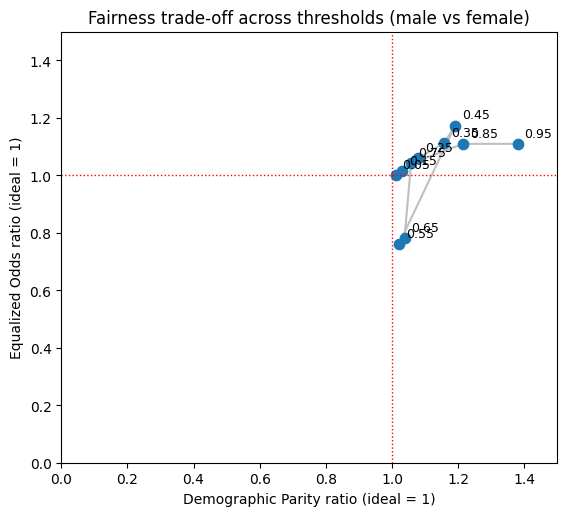

Thresholds not plotted (NaN or outside 0-1.5 axes): []


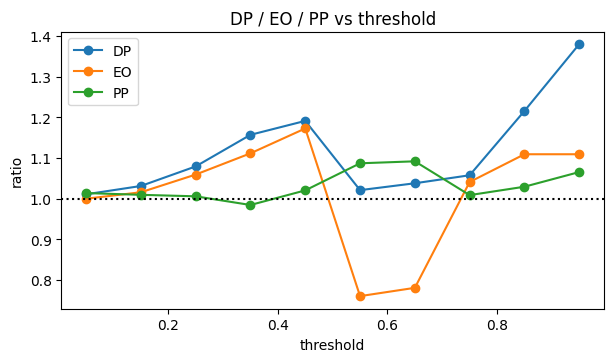

In [31]:
# Trade-off chart: x = DP, y = EO, each point labelled by threshold
fig, ax = plt.subplots(figsize=(6.4, 5.6))
ok = sweep.dropna(subset=["DP", "EO"])
ax.plot(ok.DP, ok.EO, "-", color="grey", alpha=.5, zorder=1)
ax.scatter(ok.DP, ok.EO, s=55, zorder=2)
for _, r in ok.iterrows():
    ax.annotate(f"{r.threshold:.2f}", (r.DP, r.EO), textcoords="offset points", xytext=(5, 5), fontsize=9)
ax.axvline(1, color="r", ls=":", lw=1); ax.axhline(1, color="r", ls=":", lw=1)
ax.set_xlim(0, 1.5); ax.set_ylim(0, 1.5)
ax.set_xlabel("Demographic Parity ratio (ideal = 1)"); ax.set_ylabel("Equalized Odds ratio (ideal = 1)")
ax.set_title(f"Fairness trade-off across thresholds ({labA} vs {labB})")
save_fig("fig_part24_tradeoff"); plt.show()
print("Thresholds not plotted (NaN or outside 0-1.5 axes):", sorted(set(THRESHOLDS) - set(ok[(ok.DP <= 1.5) & (ok.EO <= 1.5)].threshold)))

fig, ax = plt.subplots(figsize=(7, 3.6))
for m in ["DP", "EO", "PP"]: ax.plot(sweep.threshold, sweep[m], marker="o", label=m)
ax.axhline(1, color="k", ls=":"); ax.set_xlabel("threshold"); ax.set_ylabel("ratio"); ax.legend(); ax.set_title("DP / EO / PP vs threshold")
save_fig("fig_part24_metrics_vs_threshold"); plt.show()

In [32]:
# Quantify the trade-off: move from the threshold with best EO to the threshold with best DP
v = sweep.dropna(subset=["DP", "EO"]).copy()
t_dp = v.loc[(1 - v.DP).abs().idxmin()]            # threshold where DP is closest to 1
t_eo = v.loc[(1 - v.EO).abs().idxmin()]            # threshold where EO is closest to 1
T_FROM = None   # <-- YOU CAN CHANGE: override "from" threshold (e.g. 0.45); None = best-EO threshold
T_TO   = None   # <-- YOU CAN CHANGE: override "to" threshold   (e.g. 0.65); None = best-DP threshold
if T_FROM is not None: t_eo = v.loc[np.isclose(v.threshold, T_FROM)].iloc[0]
if T_TO is not None:   t_dp = v.loc[np.isclose(v.threshold, T_TO)].iloc[0]
print(f"Best-DP threshold = {t_dp.threshold:.2f} (DP = {t_dp.DP:.3f}, EO = {t_dp.EO:.3f}, acc = {t_dp.accuracy:.3f})")
print(f"Best-EO threshold = {t_eo.threshold:.2f} (DP = {t_eo.DP:.3f}, EO = {t_eo.EO:.3f}, acc = {t_eo.accuracy:.3f})")

if t_dp.threshold != t_eo.threshold:
    X0, Y0 = t_eo.DP, t_dp.DP; A0, B0 = t_eo.EO, t_dp.EO
    gain = (abs(1 - X0) - abs(1 - Y0)) / abs(1 - X0) * 100       # % reduction in DP gap-to-1
    loss = (abs(1 - B0) - abs(1 - A0)) / abs(1 - A0) * 100 if abs(1 - A0) > 1e-9 else np.nan   # % increase in EO gap-to-1
    print(f"\nIf you improve DP from {X0:.3f} to {Y0:.3f} (a {gain:.1f}% reduction of the gap to 1.0), "
          f"EO moves from {A0:.3f} to {B0:.3f} (a {loss:.1f}% increase of its gap). Trade-off cost = W/Z = {loss/gain:.2f}")
    RESULTS["part24_tradeoff"] = dict(t_bestDP=float(t_dp.threshold), t_bestEO=float(t_eo.threshold), DP_from=float(X0), DP_to=float(Y0),
                                      EO_from=float(A0), EO_to=float(B0), gain_pct=float(gain), loss_pct=float(loss), cost=float(loss/gain))
else:
    print("Same threshold optimises both -> no trade-off between DP and EO on this sample; compare against PP instead.")

# Does ANY threshold put all three metrics within +/-0.10 of 1?
allthree = sweep[(sweep.DP.sub(1).abs() <= .1) & (sweep.EO.sub(1).abs() <= .1) & (sweep.PP.sub(1).abs() <= .1)]
print("Thresholds with DP, EO and PP all within 0.9-1.1:", list(allthree.threshold) or "NONE")
RESULTS["part24_thresholds_all_three_ok"] = [float(x) for x in allthree.threshold]

Best-DP threshold = 0.05 (DP = 1.011, EO = 1.000, acc = 0.703)
Best-EO threshold = 0.05 (DP = 1.011, EO = 1.000, acc = 0.703)
Same threshold optimises both -> no trade-off between DP and EO on this sample; compare against PP instead.
Thresholds with DP, EO and PP all within 0.9-1.1: [0.05, 0.15, 0.25, 0.75]


In [33]:
# ----- Q7 helper: the threshold you want to defend -----
CHOSEN_T = 0.65        # <-- YOU CAN CHANGE (must be one of 0.05, 0.15, ..., 0.95)
row = sweep.loc[np.isclose(sweep.threshold, CHOSEN_T)].iloc[0]
print(f"t = {CHOSEN_T}:")
print(f"  DP = {row.DP:.3f} | EO = {row.EO:.3f} (TPR ratio {row.TPR_ratio:.3f}, FPR ratio {row.FPR_ratio:.3f}) | PP = {row.PP:.3f}")
print(f"  accuracy = {row.accuracy:.3f} (A: {row.acc_A:.3f}, B: {row.acc_B:.3f}) | % approved = {row.pct_approved:.1f}%")
print(f"  approval rate A = {row.sel_A:.3f}, B = {row.sel_B:.3f} | TPR A = {row.TPR_A:.3f}, B = {row.TPR_B:.3f} | FPR A = {row.FPR_A:.3f}, B = {row.FPR_B:.3f}")
RESULTS["part24_chosen_threshold"] = {k: (float(v) if v == v else None) for k, v in row.items()}

# ----- Q6 helper: two representative, truly-creditworthy applicants (one per group) -----
def typical(mask):
    sel = np.where(mask & (y_arr == 1))[0]
    med = np.median(p_arr[sel]); return sel[np.argmin(np.abs(p_arr[sel] - med))]
iA, iB = typical(gA), typical(gB)
cols_show = ["sex", "age", "duration", "credit_amount", "checking_status", "purpose", "savings", "employment", "housing"]
people = pd.concat([df_test.iloc[[iA]][cols_show], df_test.iloc[[iB]][cols_show]], keys=[f"Person A ({labA})", f"Person B ({labB})"])
people["P(approve)"] = [p_arr[iA], p_arr[iB]]; people["truly good?"] = [y_arr[iA], y_arr[iB]]
display(people)
dec = pd.DataFrame({"threshold": THRESHOLDS,
                    f"Person A approved?": [int(p_arr[iA] >= t) for t in THRESHOLDS],
                    f"Person B approved?": [int(p_arr[iB] >= t) for t in THRESHOLDS],
                    "TPR_A (group)": sweep.TPR_A, "TPR_B (group)": sweep.TPR_B})
display(dec)
RESULTS["q6_people"] = dict(pA=float(p_arr[iA]), pB=float(p_arr[iB]))

t = 0.65:
  DP = 1.038 | EO = 0.781 (TPR ratio 1.106, FPR ratio 0.781) | PP = 1.092
  accuracy = 0.693 (A: 0.720, B: 0.634) | % approved = 64.0%
  approval rate A = 0.647, B = 0.624 | TPR A = 0.760, B = 0.688 | FPR A = 0.377, B = 0.483


,,sex,age,duration,credit_amount,checking_status,purpose,savings,employment,housing,P(approve),truly good?
Person A (male),318,male,32,12,701,A14,A46,A61,A73,A152,0.8639,1
Person B (female),705,female,35,15,5324,A14,A40,A63,A75,A153,0.8116,1


,threshold,Person A approved?,Person B approved?,TPR_A (group),TPR_B (group)
0,0.0500,1,1,1.0000,1.0000
1,0.1500,1,1,1.0000,0.9844
2,0.2500,1,1,0.9932,0.9375
3,0.3500,1,1,0.9726,0.8750
4,0.4500,1,1,0.9452,0.7969
5,0.5500,1,1,0.8630,0.7969
6,0.6500,1,1,0.7603,0.6875
7,0.7500,1,1,0.6507,0.6250
8,0.8500,1,0,0.5342,0.4375
9,0.9500,0,0,0.2466,0.1719


## 8. Extra numbers for Part 4 (reflection) and Part 3 Q5

In [34]:
acc05 = accuracy_score(y_test, (pB >= 0.5).astype(int)); auc05 = roc_auc_score(y_test, pB)
majority = max(y_test.mean(), 1 - y_test.mean())
print(f"Overall accuracy @0.5 = {acc05:.4f} | AUC = {auc05:.4f} | majority-class baseline = {majority:.4f}")
for lab, m in [(labA, gA), (labB, gB)]:
    yh = (p_arr[m] >= 0.5).astype(int)
    print(f"  {lab:8s} n={m.sum():3d}  accuracy={np.mean(yh == y_arr[m]):.4f}  approval rate={yh.mean():.3f}  true good rate={y_arr[m].mean():.3f}")
# Bad loans approved @0.5 (the costly error in credit)
yh = (p_arr >= 0.5).astype(int)
print(f"  False positives (bad loans approved) @0.5: {int(((yh==1)&(y_arr==0)).sum())} of {int((y_arr==0).sum())} truly-bad applicants")
RESULTS["part4"] = dict(acc_05=float(acc05), auc=float(auc05), majority_baseline=float(majority),
                        fp_at_05=int(((yh == 1) & (y_arr == 0)).sum()), n_truly_bad=int((y_arr == 0).sum()))

Overall accuracy @0.5 = 0.7600 | AUC = 0.7231 | majority-class baseline = 0.7000
  male     n=207  accuracy=0.7874  approval rate=0.773  true good rate=0.705
  female   n= 93  accuracy=0.6989  approval rate=0.710  true good rate=0.688
  False positives (bad loans approved) @0.5: 44 of 90 truly-bad applicants


## 9. Numbers cheat sheet – cite these in Part 3 / Part 4 (and nowhere else)

In [35]:
import shutil
with open("outputs/results_cheat_sheet.json", "w") as f:
    json.dump(RESULTS, f, indent=2, default=lambda o: None if o != o else str(o))
print(json.dumps(RESULTS, indent=1, default=str)[:12000])   # preview; full file saved in outputs/

shutil.make_archive("outputs_bundle", "zip", "outputs")
try:
    from google.colab import files; files.download("outputs_bundle.zip")   # downloads all tables + figures
except Exception:
    print("\nSaved outputs_bundle.zip (not in Colab, so no auto-download).")

{
 "n_total": 1000,
 "approval_rate_overall": 0.7,
 "credit_amount_skew_raw": 1.9496276798326209,
 "credit_amount_skew_log": 0.1303064258083783,
 "n_train": 700,
 "n_test": 300,
 "n_features": 48,
 "test_approval_rate": 0.7,
 "part1": {
  "median_predA": 0.6975143048963943,
  "mismatch_n": 76,
  "mismatch_pct": 25.333333333333336,
  "A1B0": 0,
  "A0B1": 76,
  "flaggedA_n": 150,
  "flaggedB_n": 226,
  "flaggedB_pct": 75.33333333333333,
  "predA_outside_01": 36,
  "median_pB": 0.7682112501426165,
  "spearman": 0.9704952277247525,
  "acc_A_flag": 0.64,
  "acc_B_flag": 0.76,
  "auc_A": 0.7417989417989419,
  "auc_B": 0.723121693121693
 },
 "part21": {
  "split": "sex (A=male, B=female)",
  "predictor": "age",
  "table": [
   {
    "model": "Full dataset",
    "n": 1000,
    "coef": 0.192,
    "se": 0.0784,
    "ci_low": 0.0384,
    "ci_high": 0.3456,
    "p": 0.0143
   },
   {
    "model": "Subgroup A",
    "n": 690,
    "coef": 0.002,
    "se": 0.0955,
    "ci_low": -0.1851,
    "ci_high":

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>